In [ ]:
Opening Transmission Record/clean audio loading + sampling rate selection

In [2]:
from IPython.display import Audio
from scipy.io.wavfile import write, read
import numpy as np
import sounddevice as sd
import scipy.signal as signal
import matplotlib.pyplot as plt


file_path = "space_sound_placeholder.wav"
read_fs, audio_data = read(file_path)
print(f"Sampling rate: {read_fs} Hz")
print(f"Audio data shape: {audio_data.shape}")

Sampling rate: 48000 Hz
Audio data shape: (6963840, 2)


In [3]:
Audio(audio_data.T, rate=read_fs, normalize=True)

Nyquist justification document. We are going to use a sampling frequency of 44100 Hz as compact discs are next up. And the human ear can hear between 20Hz - 20KHz. Cite()

Anti-aliasing filter design before resampling

We Fourier transform the signal and plot it

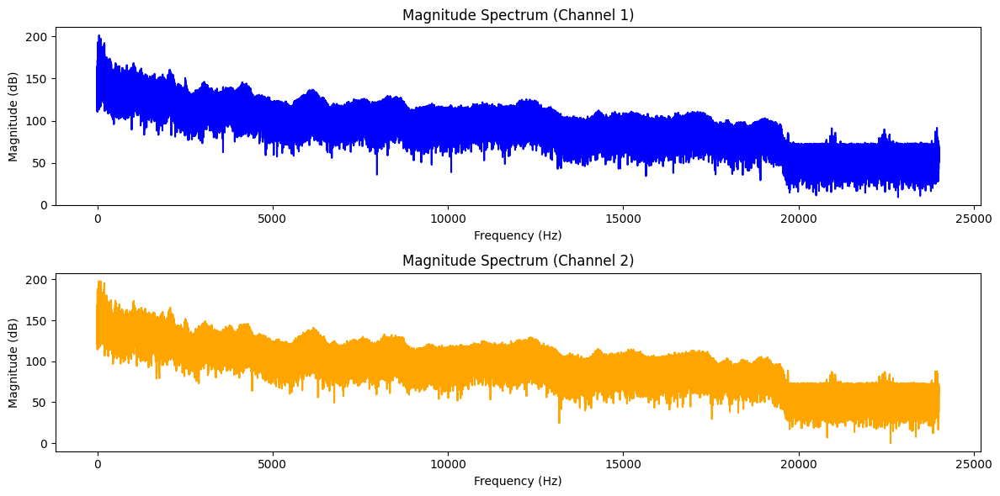

In [ ]:
fourier_transform_spectrum_one = np.fft.fft(audio_data[:, 0])  # Assuming mono channel for simplicity
fourier_transform_spectrum_two = np.fft.fft(audio_data[:, 1])  # Assuming mono channel for simplicity


# Calculating the magnitude in dB, a small offset is added to avoid loging zero
magnitude_one=np.abs(fourier_transform_spectrum_one)
magnitude_two=np.abs(fourier_transform_spectrum_two)
magnitude_db_one=20*np.log10(magnitude_one + 1e-6)
magnitude_db_two=20*np.log10(magnitude_two + 1e-6)




samplerate = read_fs

freqs_one=np.fft.fftfreq(len(fourier_transform_spectrum_one), 1/samplerate)
freqs_two=np.fft.fftfreq(len(fourier_transform_spectrum_two), 1/samplerate)

valid_indices_one = np.where((freqs_one >= 0))
valid_indices_two = np.where((freqs_two >= 0))

magnitude_db_limited_one = magnitude_db_one[valid_indices_one]
magnitude_db_limited_two = magnitude_db_two[valid_indices_two]

min_db_one = np.min(magnitude_db_limited_one)
min_db_two = np.min(magnitude_db_limited_two)
min_db = np.min([min_db_one, min_db_two])

plot_magnitude_db_one = magnitude_db_limited_one - min_db
plot_magnitude_db_two = magnitude_db_limited_two - min_db

#it can now be plotted
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(freqs_one[valid_indices_one], plot_magnitude_db_one, color='blue')
plt.title('Magnitude Spectrum (Channel 1)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.subplot(2, 1, 2)
plt.plot(freqs_two[valid_indices_two], plot_magnitude_db_two, color='orange')
plt.title('Magnitude Spectrum (Channel 2)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')

plt.tight_layout()

